# data description

About Dataset
Features are computed from a digitized image of a fine needle aspirate (FNA) of a breast mass. They describe characteristics of the cell nuclei present in the image.
n the 3-dimensional space is that described in: [K. P. Bennett and O. L. Mangasarian: "Robust Linear Programming Discrimination of Two Linearly Inseparable Sets", Optimization Methods and Software 1, 1992, 23-34].

This database is also available through the UW CS ftp server:
ftp ftp.cs.wisc.edu
cd math-prog/cpo-dataset/machine-learn/WDBC/

Also can be found on UCI Machine Learning Repository: https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+%28Diagnostic%29

Attribute Information:

1) ID number
2) Diagnosis (M = malignant, B = benign)
3-32)

Ten real-valued features are computed for each cell nucleus:

a) radius (mean of distances from center to points on the perimeter)
b) texture (standard deviation of gray-scale values)
c) perimeter
d) area
e) smoothness (local variation in radius lengths)
f) compactness (perimeter^2 / area - 1.0)
g) concavity (severity of concave portions of the contour)
h) concave points (number of concave portions of the contour)
i) symmetry
j) fractal dimension ("coastline approximation" - 1)

The mean, standard error and "worst" or largest (mean of the three
largest values) of these features were computed for each image,
resulting in 30 features. For instance, field 3 is Mean Radius, field
13 is Radius SE, field 23 is Worst Radius.

All feature values are recoded with four significant digits.

Missing attribute values: none

Class distribution: 357 benign, 212 malignant

https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data?resource=download

# imports

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')

pd.set_option("display.max_columns", None) # do not hide any columns every time we run it



# data exploration

reading the data 

In [30]:
df = pd.read_csv(r"F:\llmops mats\assignments\task 1\data\data.csv")
df.head()


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [31]:
df.shape

(569, 33)

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

checking for numirical columns

In [33]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [34]:
df.select_dtypes(include="number")

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.4630,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.0750,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.5950,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [35]:
object_data = df.select_dtypes(include="object")

print("Object columns:")
print(object_data.columns.tolist())

object_data.head()


Object columns:
['diagnosis']


,diagnosis
0,M
1,M
2,M
3,M
4,M


checking for missing value 

In [36]:
df.isna().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

will drop the unnamed col

In [37]:
df.drop(columns=["Unnamed: 32"], inplace=True)

In [38]:
df.isnull().sum().sum()

np.int64(0)

check for dublicates

In [39]:
df.duplicated().sum()

np.int64(0)

target distributions for the diagnosis column

In [40]:
df["diagnosis"].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

In [41]:
df["diagnosis"].value_counts(normalize=True) * 100

diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64

In [42]:
df["diagnosis"].unique()

<StringArray>
['M', 'B']
Length: 2, dtype: str

# what was found

only 2 unique values which is correct

B > M in the diagnosis col (imbalanced) 

no dublicates 

droped the empty col with missing values 

no datetime col 



------------------------------------------------------

re check cleaned structure

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [45]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


Target distributions 

we will detect here and resample later 
we already know b > m but will jusr visualize it 

In [48]:
print("Count:")
print(df["diagnosis"].value_counts())

print("\nPercent:")
print(df["diagnosis"].value_counts(normalize=True) * 100)


Count:
diagnosis
B    357
M    212
Name: count, dtype: int64

Percent:
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


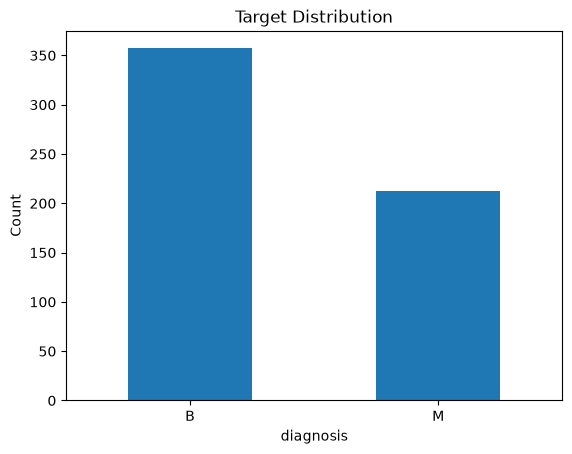

In [49]:
df["diagnosis"].value_counts().sort_index().plot(kind="bar")
plt.title("Target Distribution")
plt.xlabel("diagnosis")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

# numirical distributions

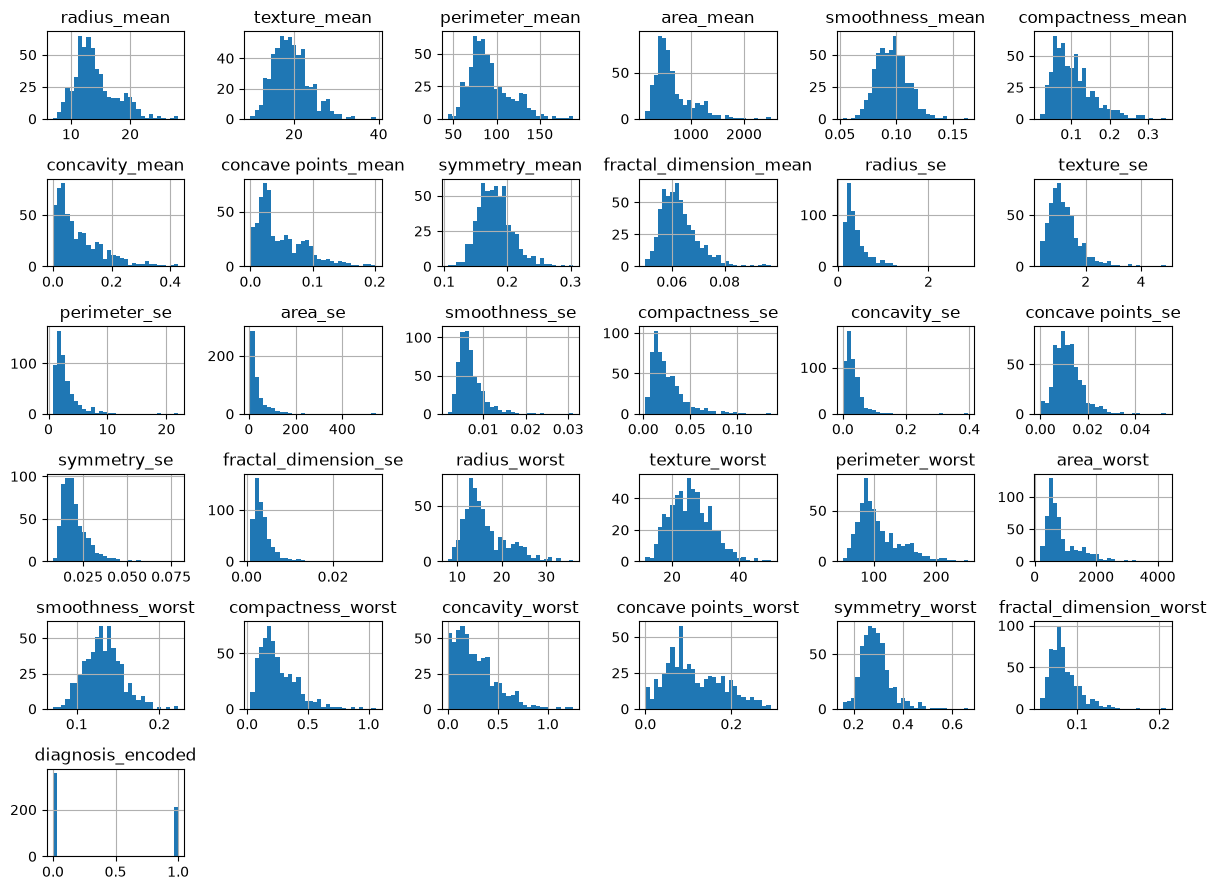

In [67]:
numeric_cols = df.select_dtypes(include="number").columns
numeric_cols = numeric_cols.drop(["id", "diagnosis"], errors="ignore")

df[numeric_cols].hist(bins=30,figsize=(12,9))
plt.tight_layout()
plt.show()

# skew check

In [51]:
df[numeric_cols].skew().round(3).sort_values(key=abs, ascending=False)
# sort for most skewd to less one
# near tan 0 will be symmetrc
# from 0.5 to 1 or from -0.5 to -1 will be moderate skew
# more than 1 or less than -1 will be strong skeew

area_se                    5.447
concavity_se               5.110
fractal_dimension_se       3.924
perimeter_se               3.444
radius_se                  3.089
smoothness_se              2.314
symmetry_se                2.195
compactness_se             1.902
area_worst                 1.859
fractal_dimension_worst    1.663
area_mean                  1.646
texture_se                 1.646
compactness_worst          1.474
concave points_se          1.445
symmetry_worst             1.434
concavity_mean             1.401
fractal_dimension_mean     1.304
compactness_mean           1.190
concave points_mean        1.171
concavity_worst            1.150
perimeter_worst            1.128
radius_worst               1.103
perimeter_mean             0.991
radius_mean                0.942
symmetry_mean              0.726
texture_mean               0.650
texture_worst              0.498
concave points_worst       0.493
smoothness_mean            0.456
smoothness_worst           0.415
dtype: flo

# Outliers

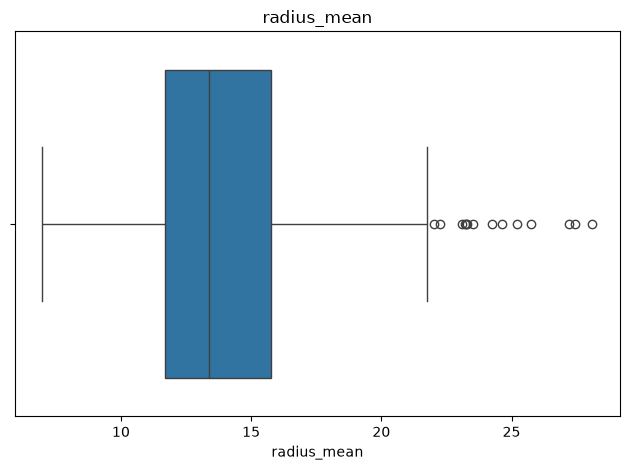

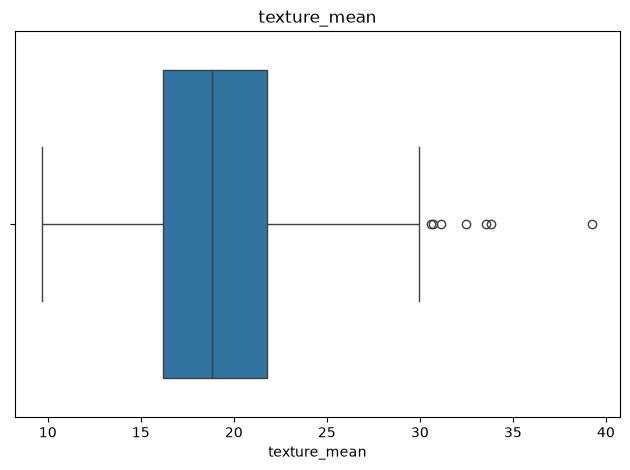

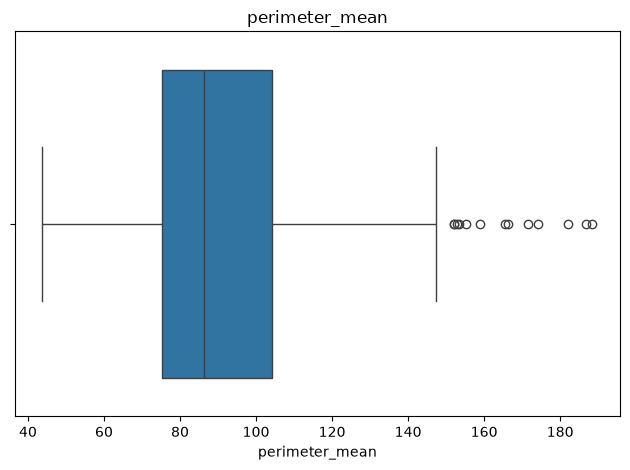

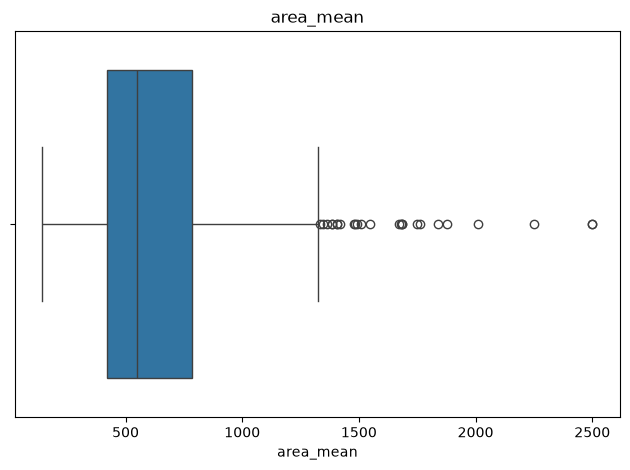

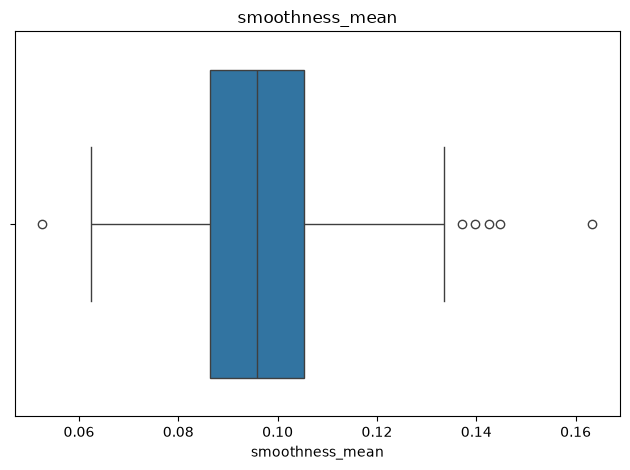

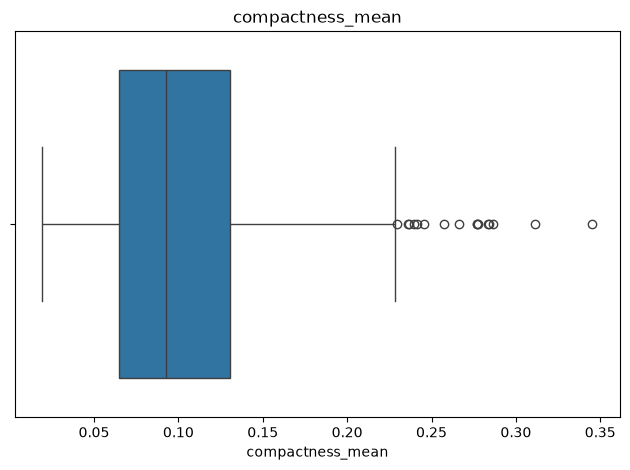

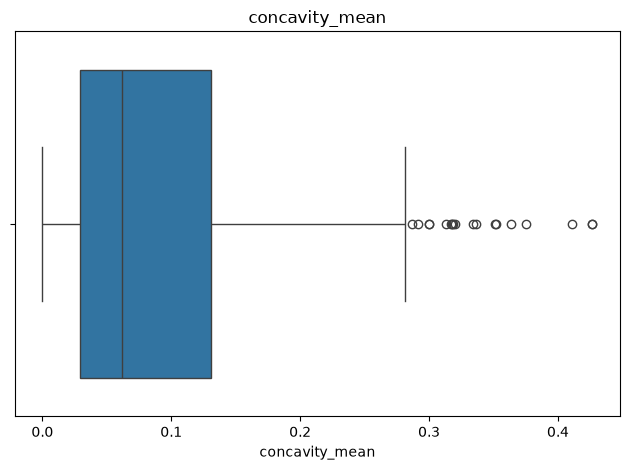

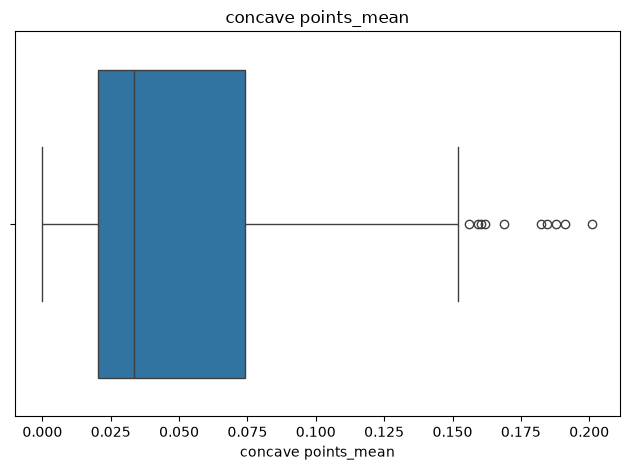

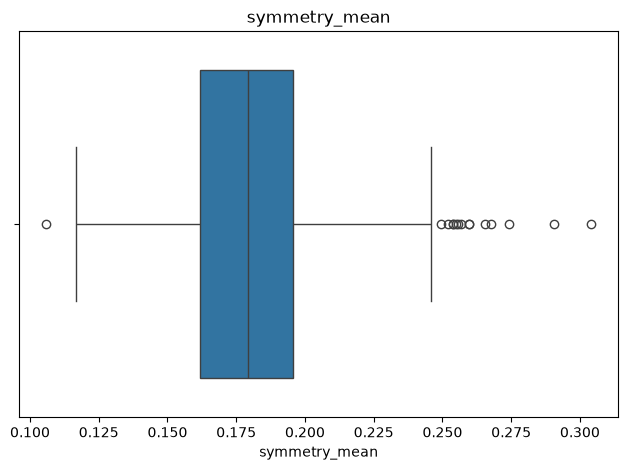

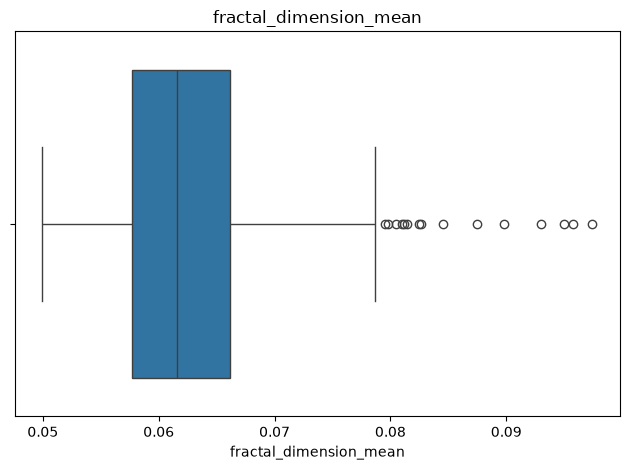

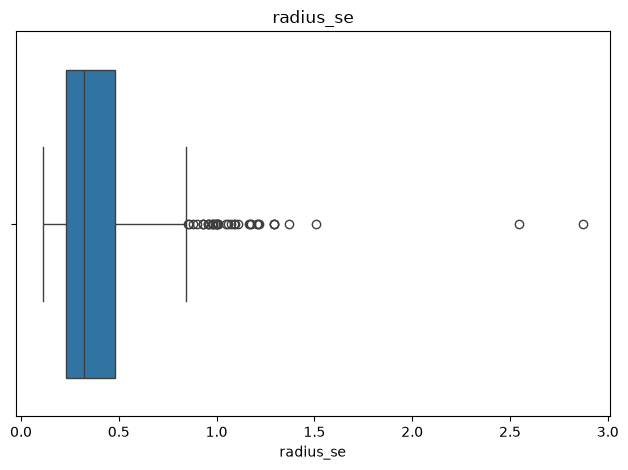

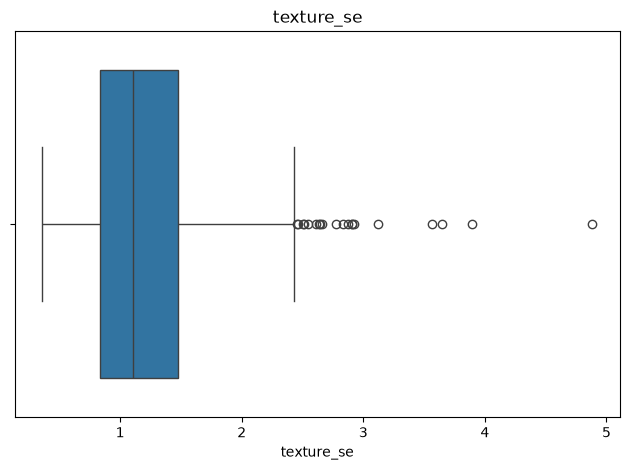

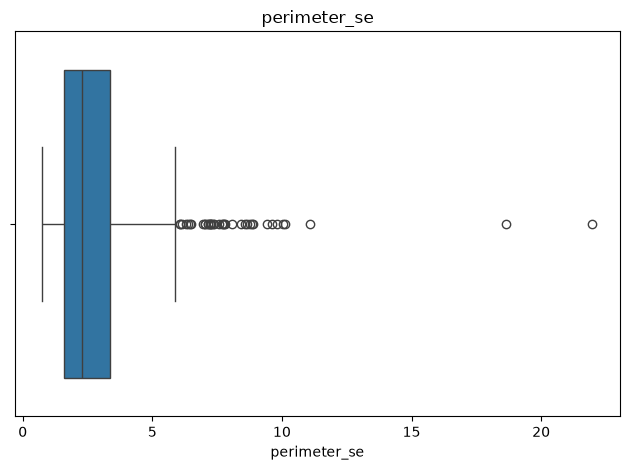

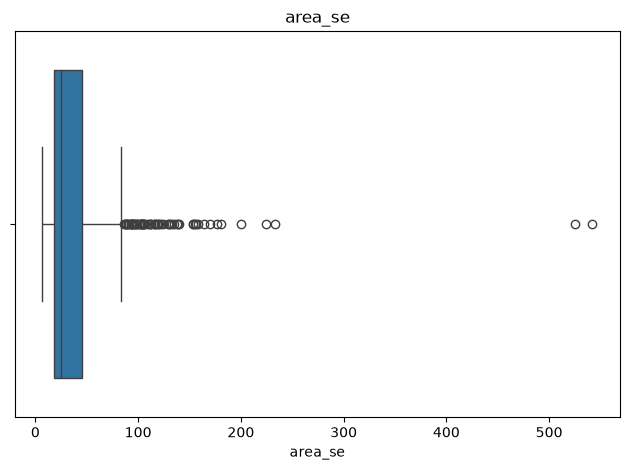

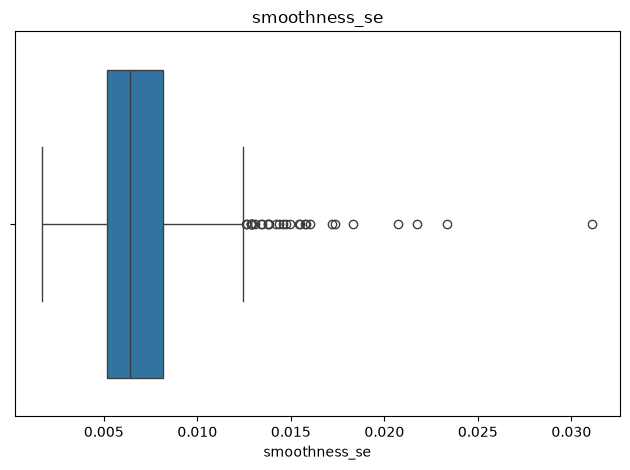

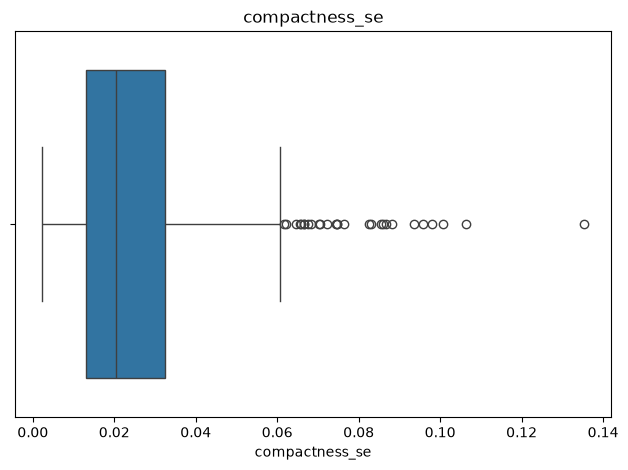

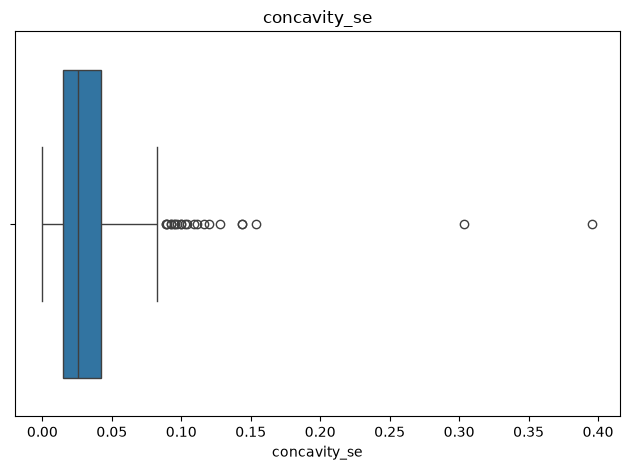

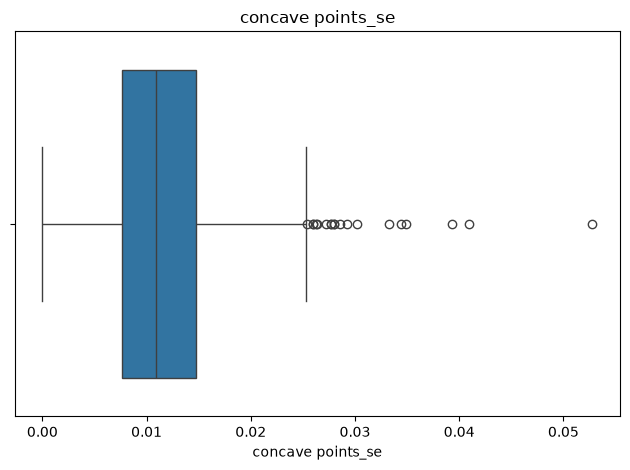

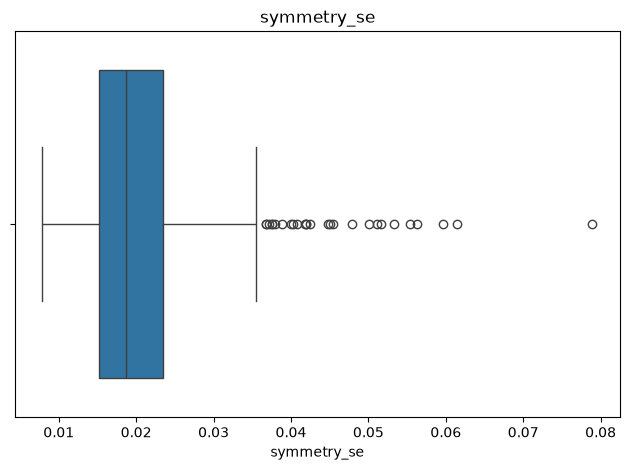

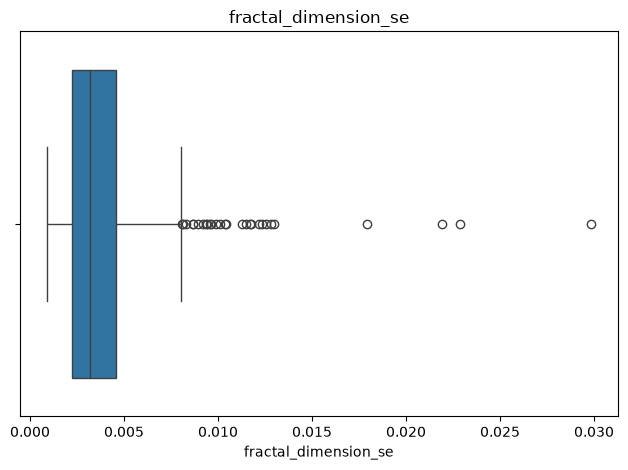

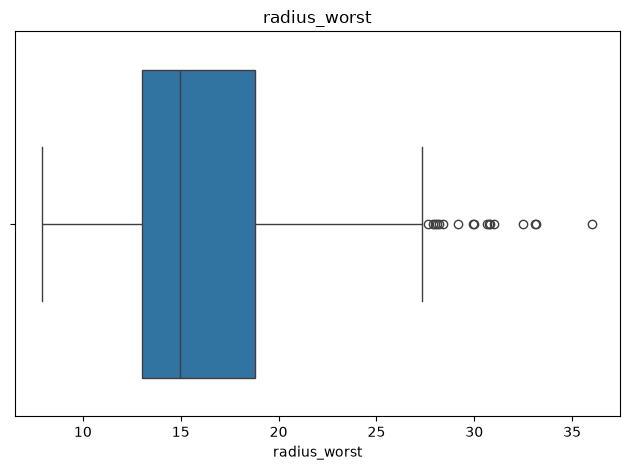

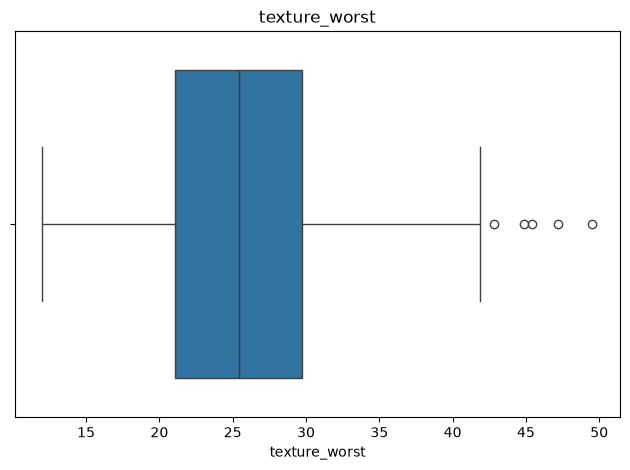

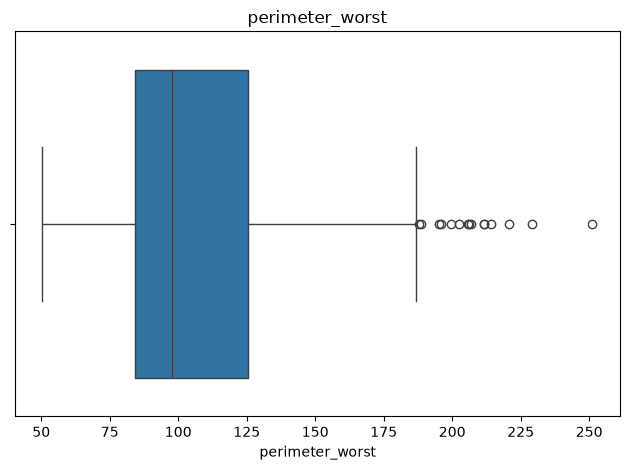

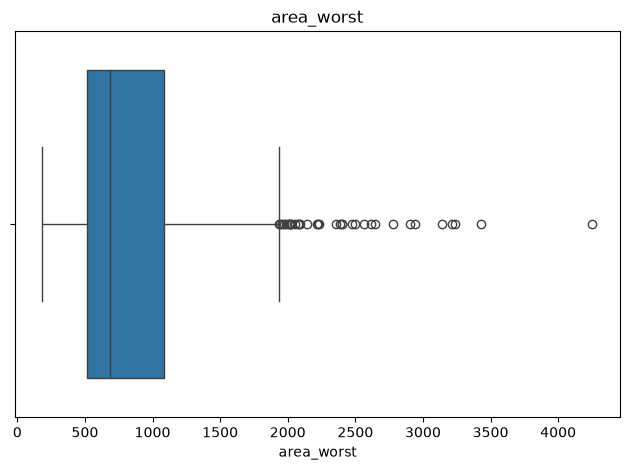

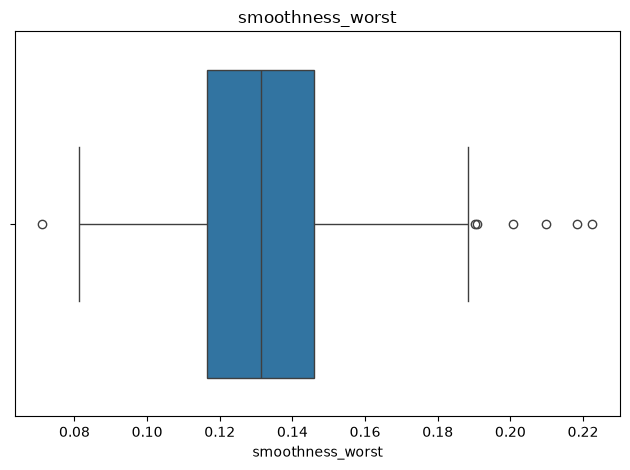

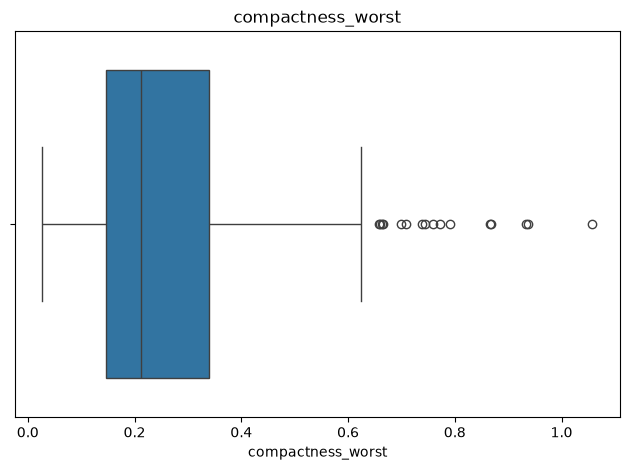

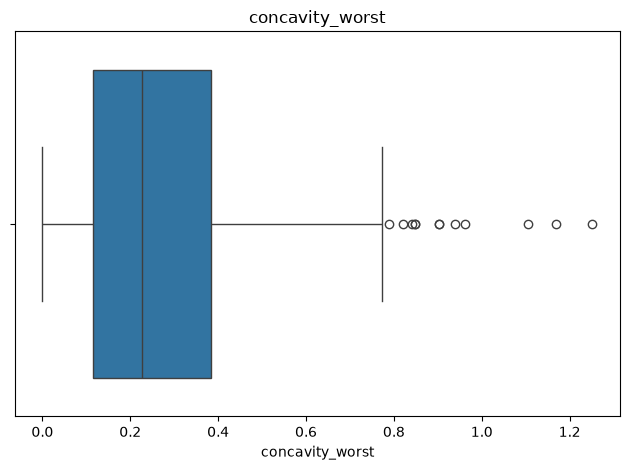

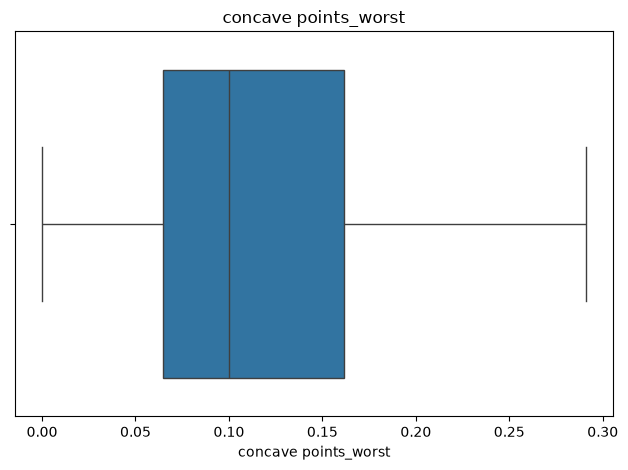

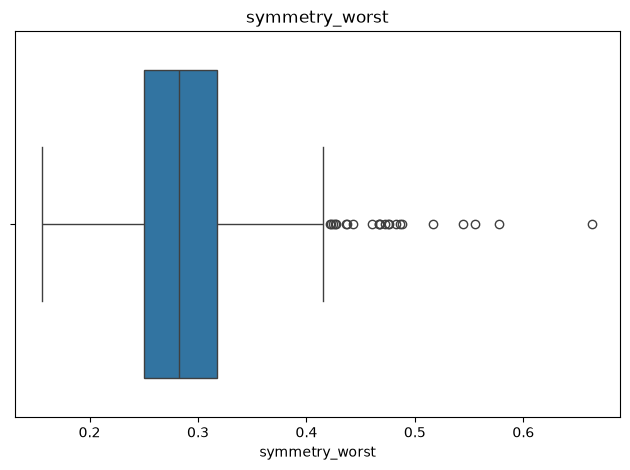

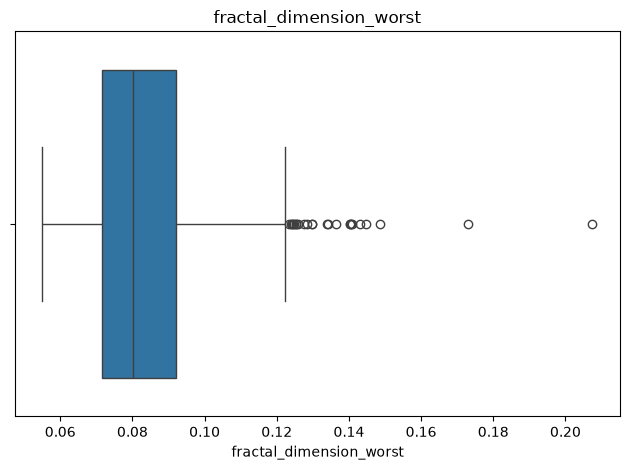

In [53]:
for col in numeric_cols:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.tight_layout()
    plt.show()

# Corroelation between numirical features

encoding the diagnosis col

In [70]:
df["diagnosis_encoded"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

In [76]:
# got an error here that numiric cols should be a list and that i have to encode the diagnosis first
# numeric_cols = numeric_cols.tolist()

corr_cols = numeric_cols + ["diagnosis_encoded"]

corr = df[corr_cols].corr().round(2)
corr

# this tells us which feature are affected by each other col  

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,diagnosis_encoded,diagnosis_encoded
radius_mean,1.00,0.32,1.00,0.99,0.17,0.51,0.68,0.82,0.15,-0.31,0.68,-0.10,0.67,0.74,-0.22,0.21,0.19,0.38,-0.10,-0.04,0.97,0.30,0.97,0.94,0.12,0.41,0.53,0.74,0.16,0.01,0.73,0.73
texture_mean,0.32,1.00,0.33,0.32,-0.02,0.24,0.30,0.29,0.07,-0.08,0.28,0.39,0.28,0.26,0.01,0.19,0.14,0.16,0.01,0.05,0.35,0.91,0.36,0.34,0.08,0.28,0.30,0.30,0.11,0.12,0.42,0.42
perimeter_mean,1.00,0.33,1.00,0.99,0.21,0.56,0.72,0.85,0.18,-0.26,0.69,-0.09,0.69,0.74,-0.20,0.25,0.23,0.41,-0.08,-0.01,0.97,0.30,0.97,0.94,0.15,0.46,0.56,0.77,0.19,0.05,0.74,0.74
area_mean,0.99,0.32,0.99,1.00,0.18,0.50,0.69,0.82,0.15,-0.28,0.73,-0.07,0.73,0.80,-0.17,0.21,0.21,0.37,-0.07,-0.02,0.96,0.29,0.96,0.96,0.12,0.39,0.51,0.72,0.14,0.00,0.71,0.71
smoothness_mean,0.17,-0.02,0.21,0.18,1.00,0.66,0.52,0.55,0.56,0.58,0.30,0.07,0.30,0.25,0.33,0.32,0.25,0.38,0.20,0.28,0.21,0.04,0.24,0.21,0.81,0.47,0.43,0.50,0.39,0.50,0.36,0.36
compactness_mean,0.51,0.24,0.56,0.50,0.66,1.00,0.88,0.83,0.60,0.57,0.50,0.05,0.55,0.46,0.14,0.74,0.57,0.64,0.23,0.51,0.54,0.25,0.59,0.51,0.57,0.87,0.82,0.82,0.51,0.69,0.60,0.60
concavity_mean,0.68,0.30,0.72,0.69,0.52,0.88,1.00,0.92,0.50,0.34,0.63,0.08,0.66,0.62,0.10,0.67,0.69,0.68,0.18,0.45,0.69,0.30,0.73,0.68,0.45,0.75,0.88,0.86,0.41,0.51,0.70,0.70
concave points_mean,0.82,0.29,0.85,0.82,0.55,0.83,0.92,1.00,0.46,0.17,0.70,0.02,0.71,0.69,0.03,0.49,0.44,0.62,0.10,0.26,0.83,0.29,0.86,0.81,0.45,0.67,0.75,0.91,0.38,0.37,0.78,0.78
symmetry_mean,0.15,0.07,0.18,0.15,0.56,0.60,0.50,0.46,1.00,0.48,0.30,0.13,0.31,0.22,0.19,0.42,0.34,0.39,0.45,0.33,0.19,0.09,0.22,0.18,0.43,0.47,0.43,0.43,0.70,0.44,0.33,0.33
fractal_dimension_mean,-0.31,-0.08,-0.26,-0.28,0.58,0.57,0.34,0.17,0.48,1.00,0.00,0.16,0.04,-0.09,0.40,0.56,0.45,0.34,0.35,0.69,-0.25,-0.05,-0.21,-0.23,0.50,0.46,0.35,0.18,0.33,0.77,-0.01,-0.01


# what was found 

most numerical features are skewd  

box plot shows outliers 

categorical data is imbalanced 

-------------------------------------------------------

# define x and y

diagnosis is the target

In [94]:
x = df.drop(columns=["diagnosis","id","diagnosis_encoded"])
y= df["diagnosis"]

In [95]:
X = df.drop(columns=["diagnosis", "id","diagnosis_encoded"])
y = df["diagnosis"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


In [96]:
y

0      M
1      M
2      M
3      M
4      M
      ..
564    M
565    M
566    M
567    M
568    B
Name: diagnosis, Length: 569, dtype: str

# train test split

In [97]:

x_train,x_test,y_train,y_test = train_test_split(X,y, test_size=0.2,random_state=42,stratify=y)

In [98]:
from sklearn.model_selection import train_test_split

xtrain,xtest,ytain,ytest = train_test_split(
    X,y,test_size=0.20,random_state=42,stratify=y
)

In [99]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y # make sure the same percentage of random of split for xtrain an xtest to be the same ratio (B > M)
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

print("\nTrain class %:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest class %:")
print((y_test.value_counts(normalize=True) * 100).round(2))


Train: (455, 30)
Test : (114, 30)

Train class %:
diagnosis
B    62.64
M    37.36
Name: proportion, dtype: float64

Test class %:
diagnosis
B    63.16
M    36.84
Name: proportion, dtype: float64


# missing values inspection

In [100]:
X_train.head(5)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
10,16.02,23.24,102.70,797.8,0.08206,0.06669,0.03299,0.03323,0.1528,0.05697,0.3795,1.1870,2.466,40.51,0.004029,0.009269,0.01101,0.007591,0.01460,0.003042,19.19,33.88,123.80,1150.0,0.11810,0.1551,0.1459,0.09975,0.2948,0.08452
170,12.32,12.39,78.85,464.1,0.10280,0.06981,0.03987,0.03700,0.1959,0.05955,0.2360,0.6656,1.670,17.43,0.008045,0.011800,0.01683,0.012410,0.01924,0.002248,13.50,15.64,86.97,549.1,0.13850,0.1266,0.1242,0.09391,0.2827,0.06771
407,12.85,21.37,82.63,514.5,0.07551,0.08316,0.06126,0.01867,0.1580,0.06114,0.4993,1.7980,2.552,41.24,0.006011,0.044800,0.05175,0.013410,0.02669,0.007731,14.40,27.01,91.63,645.8,0.09402,0.1936,0.1838,0.05601,0.2488,0.08151
430,14.90,22.53,102.10,685.0,0.09947,0.22250,0.27330,0.09711,0.2041,0.06898,0.2530,0.8749,3.466,24.19,0.006965,0.062130,0.07926,0.022340,0.01499,0.005784,16.35,27.57,125.40,832.7,0.14190,0.7090,0.9019,0.24750,0.2866,0.11550
27,18.61,20.25,122.10,1094.0,0.09440,0.10660,0.14900,0.07731,0.1697,0.05699,0.8529,1.8490,5.632,93.54,0.010750,0.027220,0.05081,0.019110,0.02293,0.004217,21.31,27.26,139.90,1403.0,0.13380,0.2117,0.3446,0.14900,0.2341,0.07421


In [101]:
missing_train = X_train.isna().sum().to_frame("Missing_Count")

missing_train["Missing_%"] = (X_train.isna().mean() * 100).round(2)

missing_train["Data_Type"] = X_train.dtypes.astype(str)

missing_train.sort_values("Missing_%", ascending=False)


,Missing_Count,Missing_%,Data_Type
radius_mean,0,0.0,float64
texture_mean,0,0.0,float64
perimeter_mean,0,0.0,float64
area_mean,0,0.0,float64
smoothness_mean,0,0.0,float64
compactness_mean,0,0.0,float64
concavity_mean,0,0.0,float64
concave points_mean,0,0.0,float64
symmetry_mean,0,0.0,float64
fractal_dimension_mean,0,0.0,float64


no missing values

# outliers diagnosis

In [102]:
numeric_check_cols = X_train.select_dtypes(include="number").columns

for col in numeric_check_cols:
    data = X_train[col]

    # IQR method
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_outliers = ((data < lower) | (data > upper)).sum()

    # Z-score method
    std = data.std()
    if std != 0:
        z = ((data - data.mean()) / std).abs()
        z_outliers = (z > 3).sum()
    else:
        z_outliers = 0

    print("\n", col)
    print("Skewness:", round(data.skew(), 3))
    print("IQR outliers:", iqr_outliers)
    print("Z > 3:", z_outliers)
    print("Min:", round(data.min(), 2))
    print("Max:", round(data.max(), 2))


 radius_mean
Skewness: 0.986
IQR outliers: 11
Z > 3: 5
Min: 6.98
Max: 28.11

 texture_mean
Skewness: 0.647
IQR outliers: 5
Z > 3: 3
Min: 9.71
Max: 39.28

 perimeter_mean
Skewness: 1.037
IQR outliers: 12
Z > 3: 5
Min: 43.79
Max: 188.5

 area_mean
Skewness: 1.72
IQR outliers: 20
Z > 3: 8
Min: 143.5
Max: 2501.0

 smoothness_mean
Skewness: 0.576
IQR outliers: 5
Z > 3: 4
Min: 0.06
Max: 0.16

 compactness_mean
Skewness: 1.271
IQR outliers: 14
Z > 3: 9
Min: 0.02
Max: 0.35

 concavity_mean
Skewness: 1.46
IQR outliers: 17
Z > 3: 8
Min: 0.0
Max: 0.43

 concave points_mean
Skewness: 1.204
IQR outliers: 9
Z > 3: 6
Min: 0.0
Max: 0.2

 symmetry_mean
Skewness: 0.738
IQR outliers: 13
Z > 3: 4
Min: 0.11
Max: 0.3

 fractal_dimension_mean
Skewness: 1.259
IQR outliers: 12
Z > 3: 4
Min: 0.05
Max: 0.1

 radius_se
Skewness: 3.181
IQR outliers: 31
Z > 3: 6
Min: 0.11
Max: 2.87

 texture_se
Skewness: 1.809
IQR outliers: 15
Z > 3: 8
Min: 0.36
Max: 4.88

 perimeter_se
Skewness: 3.517
IQR outliers: 34
Z > 3: 7
Mi

findings

all features are skewd we will use iqr clipping for that 

In [106]:
# Apply IQR clipping to all features
for col in X_train.columns:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    X_train[col] = X_train[col].clip(lower, upper)
    X_test[col] = X_test[col].clip(lower, upper)

print("IQR clipping applied to all features.")

IQR clipping applied to all features.


# check distributions

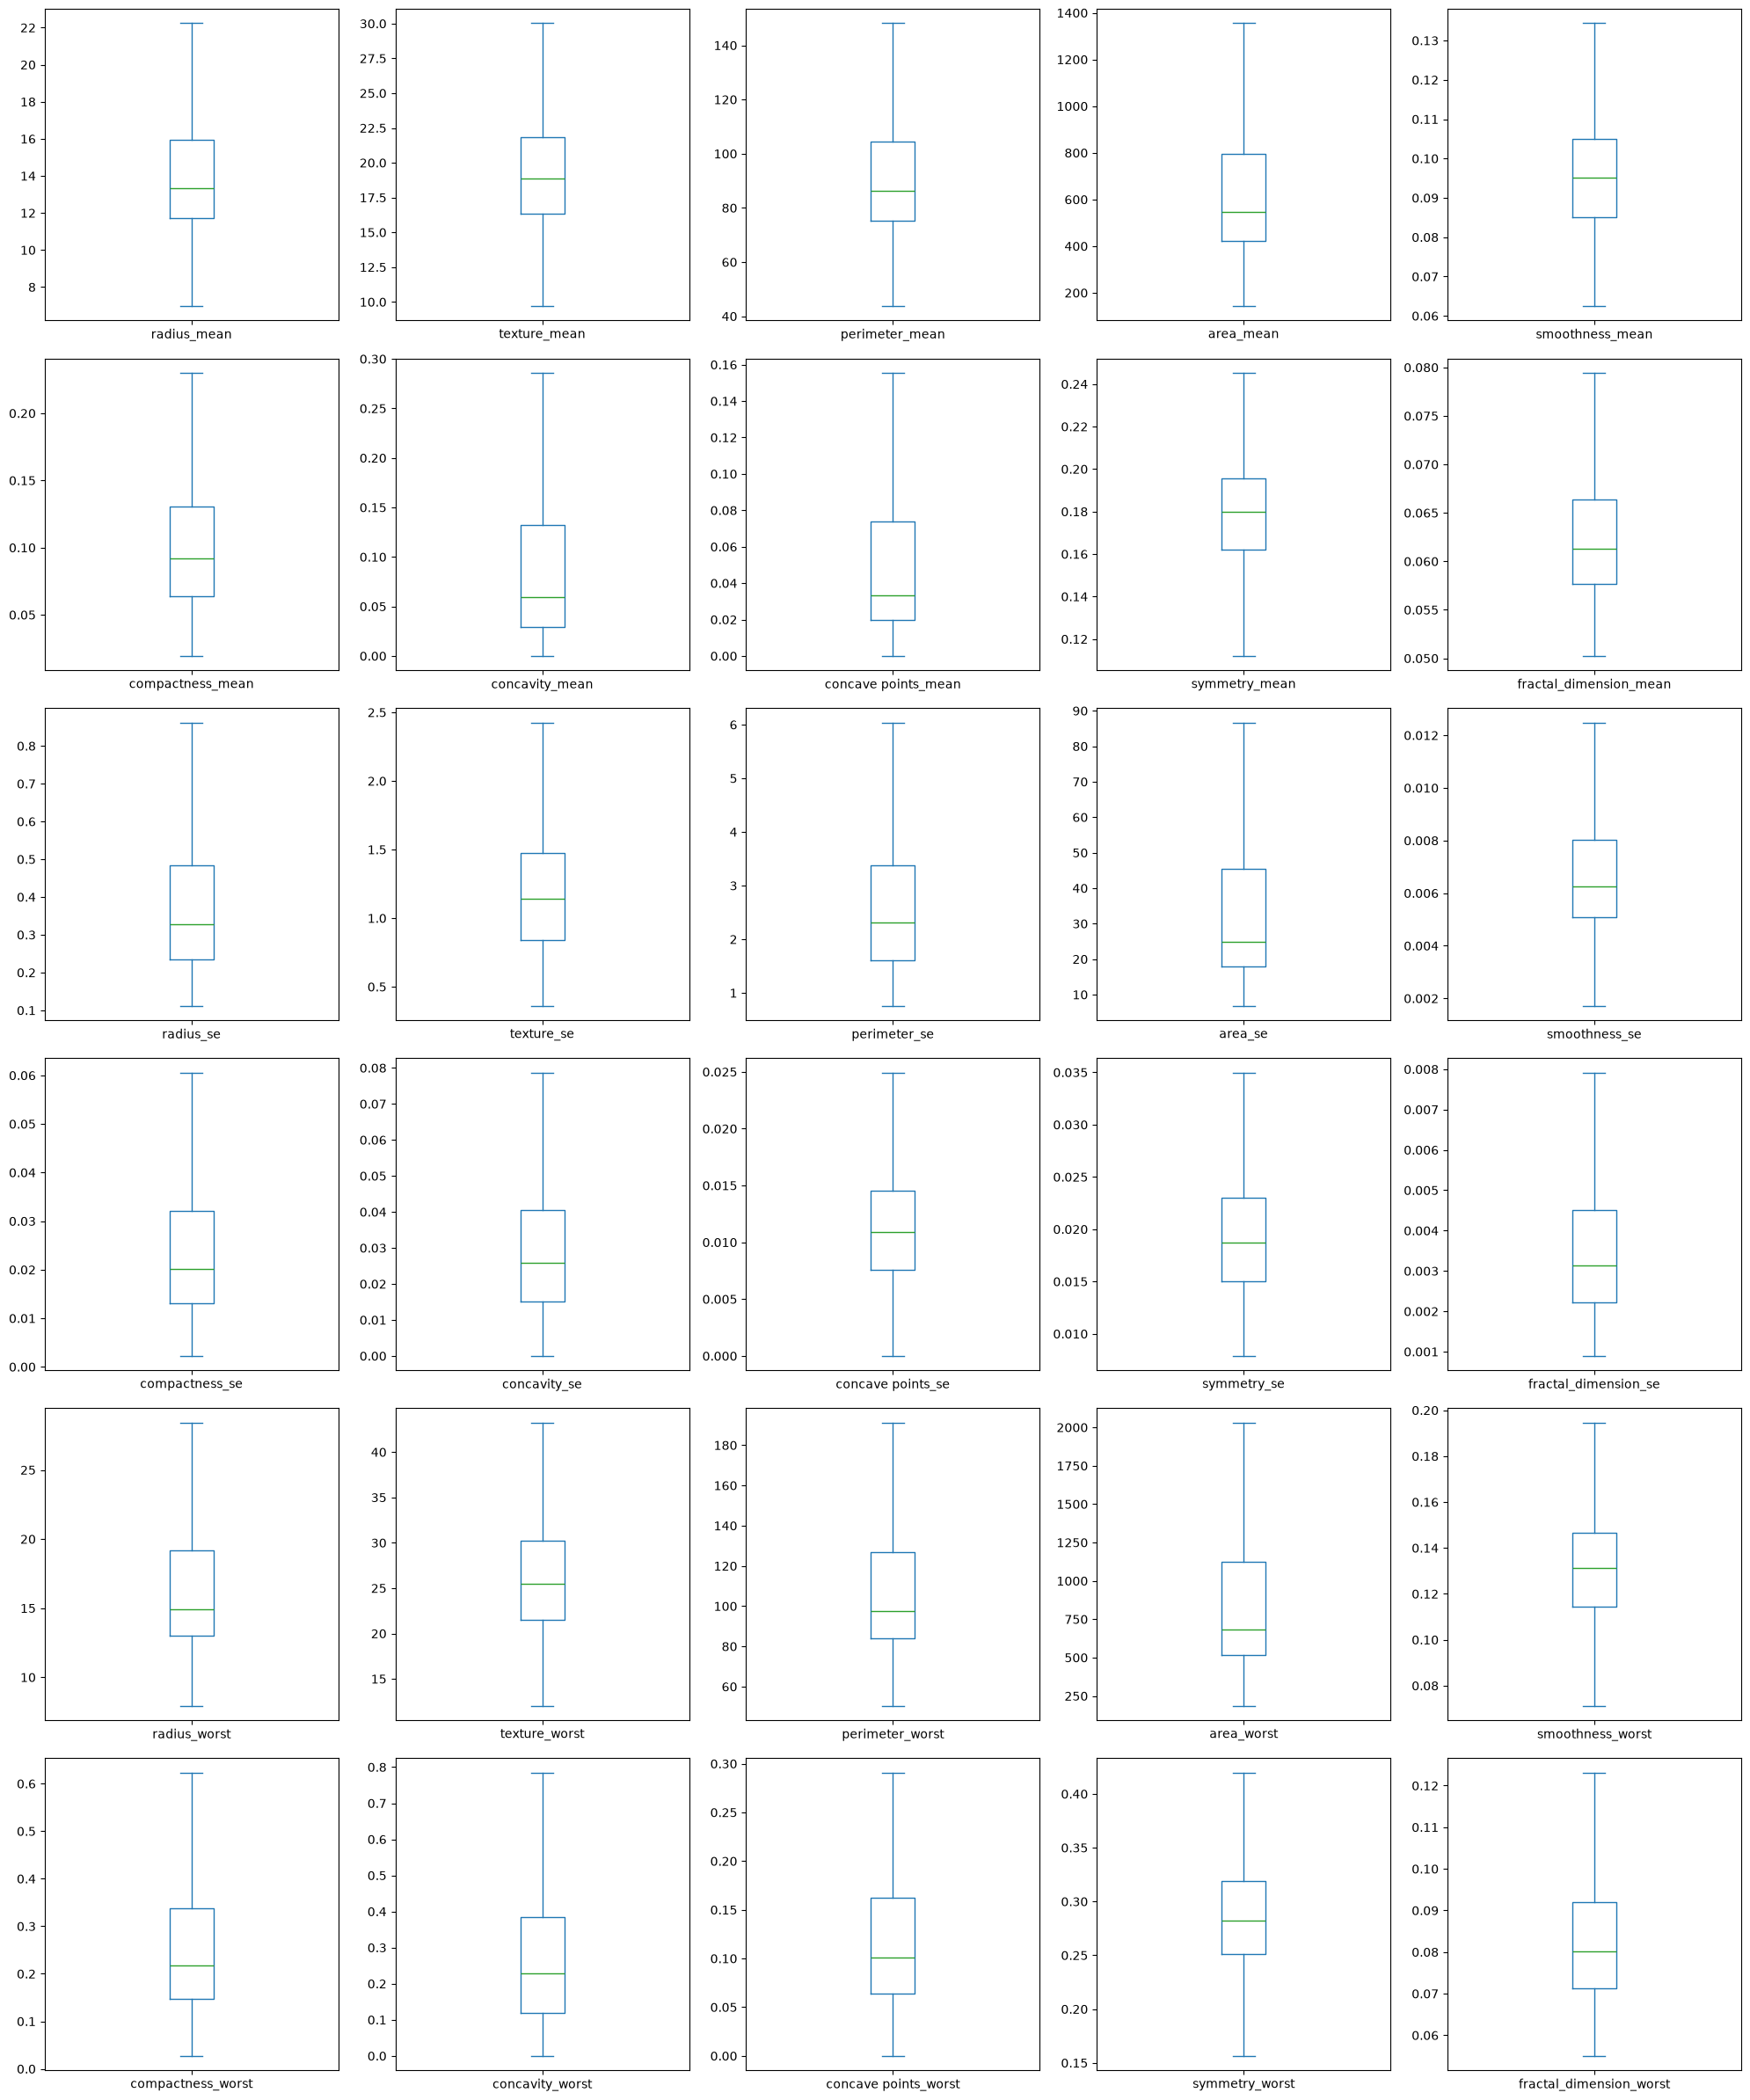

In [108]:
# Plot boxplots for all features
X_train.plot(
    kind="box",
    subplots=True,
    layout=(6, 5),
    figsize=(20, 24),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

# encoding

In [110]:
# Encode the target variable
y = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

print(y.value_counts())
print(y.head())

diagnosis
0    357
1    212
Name: count, dtype: int64
0    1
1    1
2    1
3    1
4    1
Name: diagnosis, dtype: int64


the rest is numirical data no need for encoding 

# features scaling

In [114]:

robust = RobustScaler()

X_train[X_train.columns] = robust.fit_transform(X_train)
X_test[X_test.columns] = robust.transform(X_test)

In [115]:
X_train.head(2)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
10,0.63432,0.789809,0.564497,0.670221,-0.666667,-0.384148,-0.257207,-0.002022,-0.812594,-0.495707,0.207281,0.075746,0.088111,0.568004,-0.753163,-0.572307,-0.582924,-0.477245,-0.513141,-0.039044,0.692620,0.964409,0.610055,0.769523,-0.405616,-0.323614,-0.314999,-0.012752,0.185185,0.213803
170,-0.24142,-1.184713,-0.250470,-0.219408,0.382398,-0.337311,-0.190203,0.067292,0.479760,-0.200343,-0.363636,-0.747041,-0.361480,-0.270202,0.601991,-0.439306,-0.354465,0.215688,0.067584,-0.387366,-0.230333,-1.129736,-0.249154,-0.221489,0.230889,-0.473339,-0.396471,-0.072328,0.005926,-0.597490


# final checks

In [116]:
print("Train missing values:", X_train.isna().sum().sum())
print("Test missing values :", X_test.isna().sum().sum())

print("\nTrain non-numeric columns:")
print(X_train.select_dtypes(exclude="number").columns.tolist())

print("\nTrain shape:", X_train.shape)
print("Test shape :", X_test.shape)


Train missing values: 0
Test missing values : 0

Train non-numeric columns:
[]

Train shape: (455, 30)
Test shape : (114, 30)


# handle class impalance

will use smote

In [118]:
print("Original Training distribution:")
print(y_train.value_counts())

print("\nPercent:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Original Training distribution:
diagnosis
B    285
M    170
Name: count, dtype: int64

Percent:
diagnosis
B    62.64
M    37.36
Name: proportion, dtype: float64


In [119]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Shape:", X_train_smote.shape)
print(y_train_smote.value_counts())

Shape: (570, 30)
diagnosis
M    285
B    285
Name: count, dtype: int64


# saving cleaned data

In [120]:
train_ready = X_train.copy()
train_ready["diagnosis"] = y_train

test_ready = X_test.copy()
test_ready["diagnosis"] = y_test

train_ready.to_csv("breast_cancer_data_train.csv", index=False)
test_ready.to_csv("breast_cancer_data_test.csv", index=False)

print("Saved train:", train_ready.shape)
print("Saved test :", test_ready.shape)

Saved train: (455, 31)
Saved test : (114, 31)


---------------------------------

# training the model

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# loading the cleaned csv

In [15]:
train_ready = pd.read_csv("breast_cancer_data_train.csv")
test_ready = pd.read_csv("breast_cancer_data_test.csv")

print("Train shape:", train_ready.shape)
print("Test shape:", test_ready.shape)

Train shape: (455, 31)
Test shape: (114, 31)


Separate features and target

In [16]:
X_train = train_ready.drop(columns=["diagnosis"])
y_train = train_ready["diagnosis"]

X_test = test_ready.drop(columns=["diagnosis"])
y_test = test_ready["diagnosis"]

Accuracy: 0.9736842105263158

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



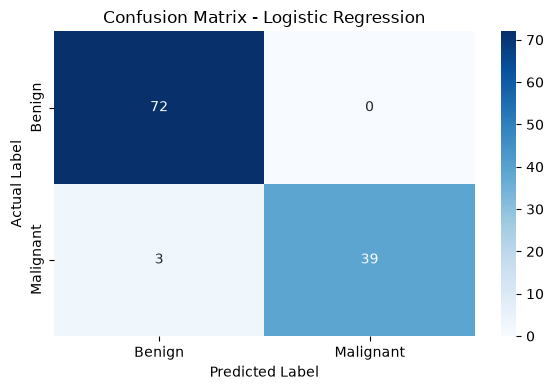

In [18]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

# saving the model using joblib

In [19]:
import joblib

joblib.dump(model, "breast_cancer_model.joblib")

print("Model saved successfully!")

Model saved successfully!
